<a href="https://colab.research.google.com/github/Deepakchakra/HDFS_SYSTEM/blob/main/HDFS_File_Management_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#install java
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

!java -version


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  openjdk-17-jre-headless
Suggested packages:
  openjdk-17-demo openjdk-17-source libnss-mdns fonts-dejavu-extra
  fonts-ipafont-gothic fonts-ipafont-mincho fonts-wqy-microhei
  | fonts-wqy-zenhei fonts-indic
The following NEW packages will be installed:
  openjdk-17-jdk-headless openjdk-17-jre-headless
0 upgraded, 2 newly installed, 0 to remove and 24 not upgraded.
Need to get 120 MB of archives.
After this operation, 272 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 openjdk-17-jre-headless amd64 17.0.20.1+1-1~24.04 [48.1 MB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 open

In [ ]:
#install hadoop
%cd /content

!wget -q https://archive.apache.org/dist/hadoop/common/hadoop-3.4.2/hadoop-3.4.2.tar.gz
!tar -xzf hadoop-3.4.2.tar.gz

print("Hadoop installation files extracted.")
! /content/hadoop-3.4.2/bin/hadoop version


/content
Hadoop installation files extracted.
Hadoop 3.4.2
Source code repository https://github.com/apache/hadoop.git -r 84e8b89ee2ebe6923691205b9e171badde7a495c
Compiled by ahmarsu on 2025-08-20T10:30Z
Compiled on platform linux-x86_64
Compiled with protoc 3.23.4
From source with checksum fa94c67d4b4be021b9e9515c9b0f7b6
This command was run using /content/hadoop-3.4.2/share/hadoop/common/hadoop-common-3.4.2.jar


In [ ]:
#configure hadoop

import os

HADOOP_HOME = "/content/hadoop-3.4.2"
JAVA_HOME = "/usr/lib/jvm/java-17-openjdk-amd64"

os.environ["JAVA_HOME"] = JAVA_HOME
os.environ["HADOOP_HOME"] = HADOOP_HOME
os.environ["HADOOP_CONF_DIR"] = f"{HADOOP_HOME}/etc/hadoop"
os.environ["PATH"] = (
    f"{HADOOP_HOME}/bin:{HADOOP_HOME}/sbin:"
    f"{JAVA_HOME}/bin:" + os.environ["PATH"]
)

# Hadoop environment configuration
with open(f"{HADOOP_HOME}/etc/hadoop/hadoop-env.sh", "a") as f:
    f.write(f"\nexport JAVA_HOME={JAVA_HOME}\n")
    f.write("\nexport HDFS_NAMENODE_USER=root\n")
    f.write("export HDFS_DATANODE_USER=root\n")
    f.write("export HDFS_SECONDARYNAMENODE_USER=root\n")

# HDFS configuration
core_site = """<?xml version="1.0"?>
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>
"""

hdfs_site = """<?xml version="1.0"?>
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file:///content/hadoopdata/namenode</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file:///content/hadoopdata/datanode</value>
    </property>
</configuration>
"""

with open(f"{HADOOP_HOME}/etc/hadoop/core-site.xml", "w") as f:
    f.write(core_site)

with open(f"{HADOOP_HOME}/etc/hadoop/hdfs-site.xml", "w") as f:
    f.write(hdfs_site)

os.makedirs("/content/hadoopdata/namenode", exist_ok=True)
os.makedirs("/content/hadoopdata/datanode", exist_ok=True)

print("Hadoop configuration completed.")


Hadoop configuration completed.


In [ ]:
#initialize HDFS
!hdfs namenode -format -force


2026-10-11 12:36:31,132 INFO namenode.NameNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting NameNode
STARTUP_MSG:   host = 5c1e770e8ba3/172.28.0.12
STARTUP_MSG:   args = [-format, -force]
STARTUP_MSG:   version = 3.4.2
STARTUP_MSG:   classpath = /content/hadoop-3.4.2/etc/hadoop:/content/hadoop-3.4.2/share/hadoop/common/lib/jsp-api-2.1.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/netty-codec-haproxy-4.1.118.Final.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/guava-27.0-jre.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/jetty-http-9.4.57.v20241219.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/netty-transport-native-unix-common-4.1.118.Final.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/metrics-core-3.2.4.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/jettison-1.5.4.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/kerb-util-2.0.3.jar:/content/hadoop-3.4.2/share/hadoop/common/lib/commons-compress-1.26.1.jar:/cont

In [ ]:
import os
import subprocess
import time

env = os.environ.copy()
env["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
env["HADOOP_HOME"] = "/content/hadoop-3.4.2"
env["HADOOP_CONF_DIR"] = "/content/hadoop-3.4.2/etc/hadoop"
env["HDFS_NAMENODE_USER"] = "root"
env["HDFS_DATANODE_USER"] = "root"
env["HDFS_SECONDARYNAMENODE_USER"] = "root"

commands = [
    ["hdfs", "--daemon", "start", "namenode"],
    ["hdfs", "--daemon", "start", "datanode"],
    ["hdfs", "--daemon", "start", "secondarynamenode"]
]

for cmd in commands:
    result = subprocess.run(
        cmd, env=env, capture_output=True, text=True
    )
    print("$", " ".join(cmd))
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print("Exit code:", result.returncode)
    if result.returncode != 0:
        raise RuntimeError("HDFS startup failed. Stop here and share the error.")

time.sleep(3)
subprocess.run(["jps"], env=env)


$ hdfs --daemon start namenode

Exit code: 0
$ hdfs --daemon start datanode

Exit code: 0
$ hdfs --daemon start secondarynamenode

Exit code: 0


CompletedProcess(args=['jps'], returncode=0)

In [ ]:
#1.creating directory in HDFS

!hdfs dfs -mkdir -p /user/student/project
!hdfs dfs -ls /user/student


Found 1 items
drwxr-xr-x   - root supergroup          0 2026-10-11 14:29 /user/student/project


In [ ]:
#create file operation
# Create a sample file in local storage
with open("/content/sample.txt", "w") as f:
    f.write("Hello HDFS!\n")
    f.write("Project: HDFS File Management System\n")
    f.write("Operation: Upload, Retrieve, Copy, Move and Delete\n")
    f.write("this is the BIG DATA project")

print("Sample file created successfully.")

# Display the contents
!cat /content/sample.txt


Sample file created successfully.
Hello HDFS!
Project: HDFS File Management System
Operation: Upload, Retrieve, Copy, Move and Delete
this is the BIG DATA project

In [ ]:
#2.upload operation
# Upload the local file to HDFS
!hdfs dfs -put /content/sample.txt /user/student/project/

# Verify the uploaded file
!hdfs dfs -ls /user/student/project


Found 1 items
-rw-r--r--   1 root supergroup        128 2026-10-11 14:29 /user/student/project/sample.txt


In [ ]:
#3.retrieving operation
# Download the file from HDFS to local storage
!hdfs dfs -get /user/student/project/sample.txt /content/Retrieved_sample.txt

# Display the retrieved contents
!cat /content/Retrieved_sample.txt


Hello HDFS!
Project: HDFS File Management System
Operation: Upload, Retrieve, Copy, Move and Delete
this is the BIG DATA project

In [ ]:
#4.copy operation
!hdfs dfs -cp \
  /user/student/project/sample.txt \
  /user/student/project/copy.txt

!hdfs dfs -ls /user/student/project
!hdfs dfs -cat /user/student/project/copy.txt


Found 2 items
-rw-r--r--   1 root supergroup        128 2026-10-11 14:32 /user/student/project/copy.txt
-rw-r--r--   1 root supergroup        128 2026-10-11 14:29 /user/student/project/sample.txt
Hello HDFS!
Project: HDFS File Management System
Operation: Upload, Retrieve, Copy, Move and Delete
this is the BIG DATA project

In [ ]:
#5.move or rename operation
!hdfs dfs -mv \
  /user/student/project/copy.txt \
  /user/student/project/sample_1.txt

!hdfs dfs -ls /user/student/project


Found 2 items
-rw-r--r--   1 root supergroup        128 2026-10-11 14:29 /user/student/project/sample.txt
-rw-r--r--   1 root supergroup        128 2026-10-11 14:32 /user/student/project/sample_1.txt


In [ ]:
#6.delete operation
!hdfs dfs -rm /user/student/project/sample_1.txt
!hdfs dfs -ls /user/student/project


Deleted /user/student/project/sample_1.txt
Found 1 items
-rw-r--r--   1 root supergroup        128 2026-10-11 14:29 /user/student/project/sample.txt


In [ ]:
# Create a test directory
!hdfs dfs -mkdir -p /deepu/project

# Create a local text file and write data into it
with open("/content/test.txt", "w") as f:
    f.write("testing the file and performing the HDFS operations\n")
print("Text file created with data.")

# upload
!hdfs dfs -put /content/test.txt /deepu/project



Text file created with data.


In [ ]:
#display the data present in the file
!hdfs dfs -cat /deepu/project/test.txt

testing the file and performing the HDFS operations


In [ ]:
#displaying the list of files
!hdfs dfs -ls /deepu/project

Found 1 items
-rw-r--r--   1 root supergroup         52 2026-10-11 13:21 /deepu/project/test.txt


In [ ]:
#renaming the exisiting file
!hdfs dfs -mv /deepu/project/test.txt /deepu/project/final.txt
!hdfs dfs -ls /deepu/project

mv: `/deepu/project/final.txt': File exists
Found 1 items
-rw-r--r--   1 root supergroup         52 2026-10-11 13:21 /deepu/project/final.txt


In [ ]:
#deleting the file
!hdfs dfs -rm /deepu/project/final.txt
!hdfs dfs -ls /deepu/project

Deleted /deepu/project/final.txt


In [ ]:
!hdfs dfs -ls /user/student/project


Found 2 items
-rw-r--r--   1 root supergroup        100 2026-10-11 13:10 /user/student/project/renamed.txt
-rw-r--r--   1 root supergroup        100 2026-10-11 12:39 /user/student/project/sample.txt


In [ ]:
!hdfs dfs -rm /user/student/project/renamed.txt

Deleted /user/student/project/renamed.txt


In [ ]:
!hdfs dfs -rmdir /user/student /user

In [ ]:
!hdfs dfs -ls /

Found 1 items
drwxr-xr-x   - root supergroup          0 2026-10-11 13:21 /deepu


In [ ]:
!hdfs dfs -mkdir /last

In [ ]:
!hdfs dfs -ls /

Found 2 items
drwxr-xr-x   - root supergroup          0 2026-10-11 13:21 /deepu
drwxr-xr-x   - root supergroup          0 2026-10-11 14:19 /last


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving car.png to car.png


In [ ]:
!hdfs dfs -put /content/car.png /user/student/project/

In [ ]:
!hdfs dfs -ls /user/student/project/

Found 2 items
-rw-r--r--   1 root supergroup    3783671 2026-10-11 14:40 /user/student/project/car.png
-rw-r--r--   1 root supergroup        128 2026-10-11 14:29 /user/student/project/sample.txt


In [ ]:
!hdfs dfs -get /user/student/project/car.png /content/retrieved_photo.png

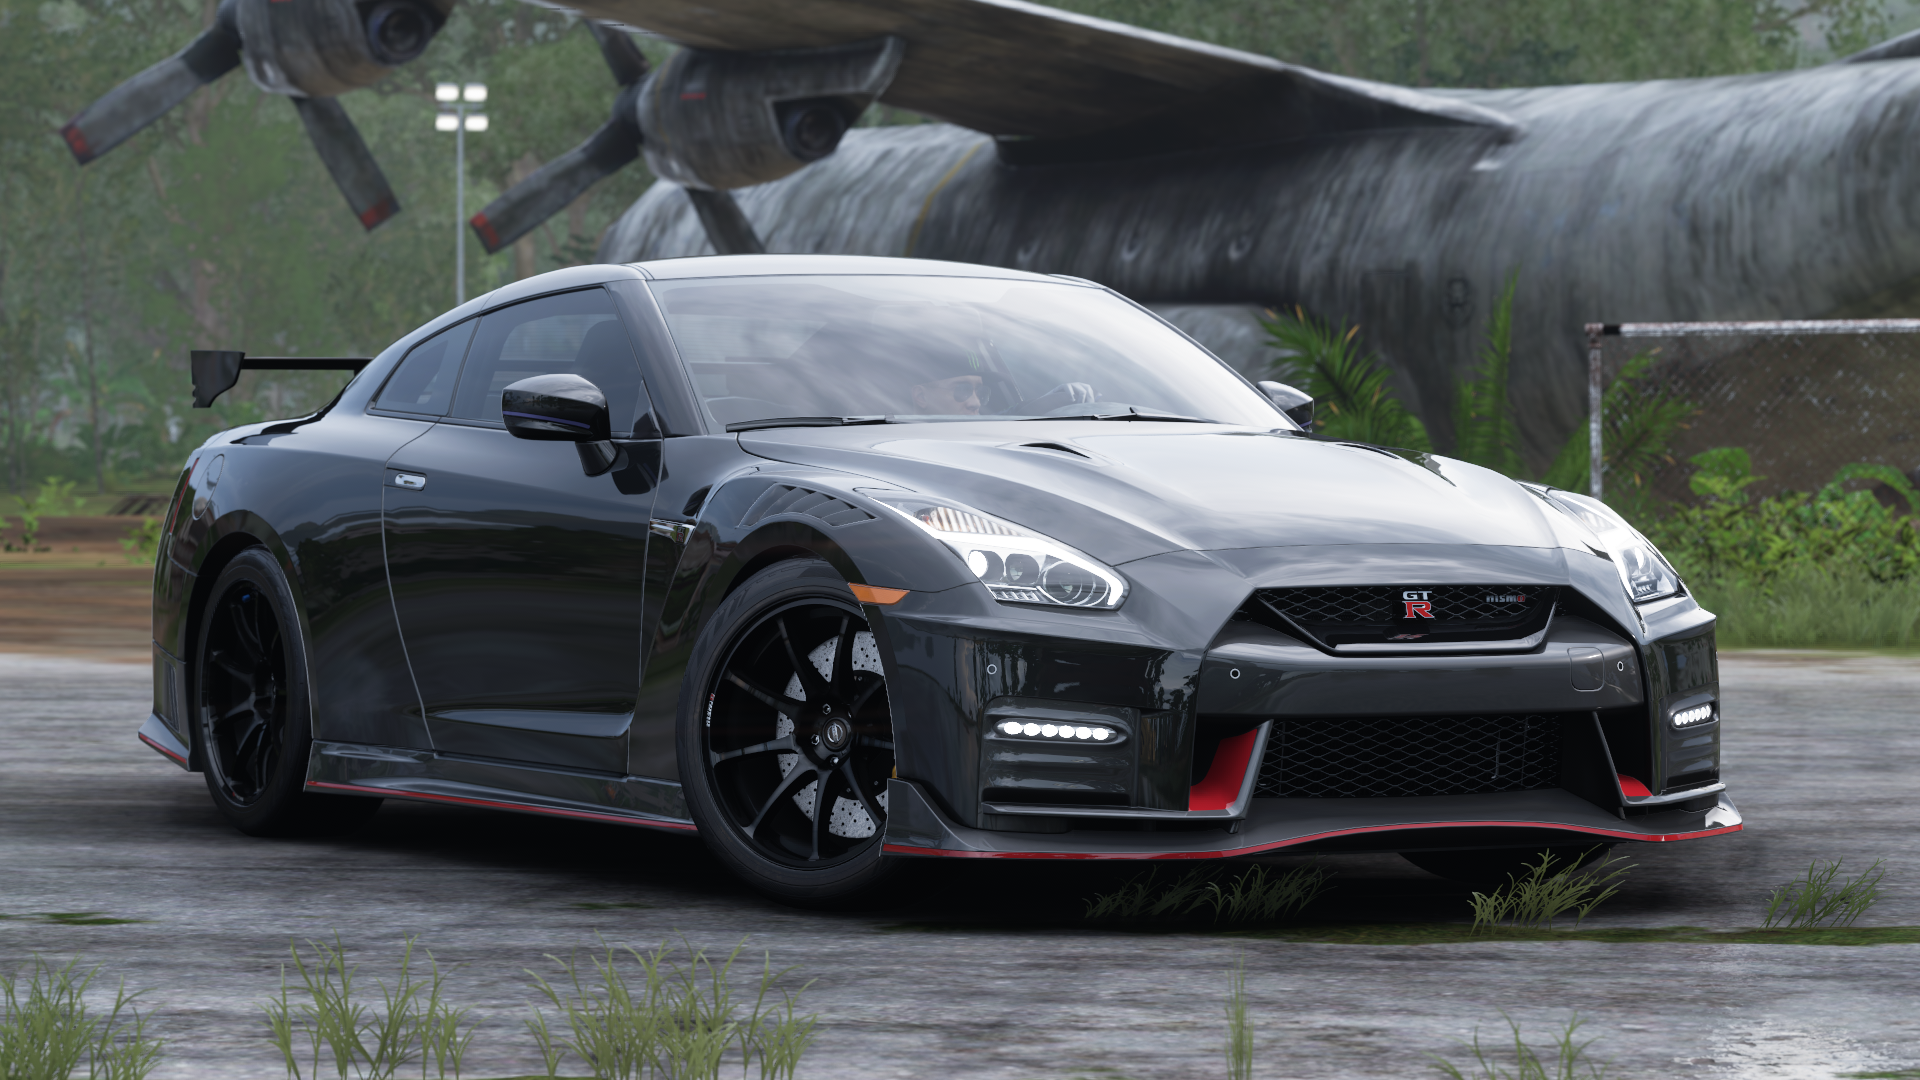

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/retrieved_photo.png"))